# Random Forest
This notebook contains the code for training and evaluating a Random Forest model for binary failure detection and multiclass prediction of the failure mode.

### Imports

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

# Part A: Binary

**Data and features.** The 75/25 stratified split (`random_state=42`) comes from `load_split("binary")`. We load only the training set (7500 rows, 3.39% failures); all tuning uses repeated stratified 5-fold cross-validation inside it, and the test set is not touched.

We use the 9 features chosen in feature selection: rotational speed, torque, tool wear, temperature difference, power, strain and the three `Type` columns. Air and process temperature were dropped because removing them left the validation F1 unchanged (0.855 against 0.854). A Random Forest does not need scaled inputs.

**Class imbalance.** About 3.4% of the rows are failures, so accuracy is misleading (always predicting "no failure" gives ~96.6%). We judge models by precision, recall and F1 of class 1 and track missed failures (FN) and false alarms (FP).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import ParameterSampler
import json

from src.splits import load_split
from src.evaluate import evaluate, metrics_at_threshold, threshold_table, summarize, log_result, THRESHOLDS
from src.models_rf import make_rf, BASELINE, SWEEPS, SEARCH_SPACE, load_selected_features

ROOT = pathlib.Path.cwd().parent
(ROOT / "results" / "figures").mkdir(parents=True, exist_ok=True)

In [3]:
X_train, _, y_train, _ = load_split("binary")
SELECTED = load_selected_features()
X_train = X_train[SELECTED]
print(X_train.shape, f"{y_train.mean():.3%}")
print(SELECTED)

(7500, 9) 3.387%
['Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temp diff [K]', 'Power [W]', 'Strain [min Nm]', 'Type_L', 'Type_M', 'Type_H']


## Fuctions

`run_config(name, params)` builds the forest with `make_rf(**params)`, runs the 5×3 cross-validation with `evaluate` and returns one row per decision threshold, using eight thresholds (`THRESHOLDS`: 0.1 to 0.5). The per-fold probabilities are kept, so changing the threshold needs no retraining.

`run_and_log` applies the selection rule to each configuration (among the thresholds with mean recall ≥ 0.75, the highest F1) and appends that row to `results/tuning_log.csv`. If no threshold reaches the floor, it logs the one with the highest recall.

**Selection rule** Among the (configuration, threshold) pairs with mean validation recall of at least 0.75, pick the highest F1. The 0.75 floor is a judgement based on that a missed failure is more costly, not a result derived from the data.

In [4]:
import time
R_MIN = 0.75
FEATURE_SET = "selected 9 (T7)"
PARAMS = {}

def run_config(name, params, seed=42):
    eff = {**BASELINE, **params}
    t0 = time.time()
    _, probas = evaluate(make_rf(**params), X_train, y_train, random_state=seed)
    tt = threshold_table(probas, THRESHOLDS)
    tt.insert(0, "config", name)
    for k, v in eff.items():
        tt[k] = str(v)
    tt["seconds"] = round(time.time() - t0)
    return tt, probas

def best_per_config(summary, r_min=R_MIN):
    """Per configuration: the threshold with the highest F1 among those with recall >= r_min."""
    ok = summary[summary["recall_mean"] >= r_min]
    return ok.loc[ok.groupby("config")["f1_mean"].idxmax()]

def run_and_log(name, params):
    PARAMS[name] = params
    tt, probas = run_config(name, params)
    ok = tt[tt["recall_mean"] >= R_MIN]
    row = ok.loc[ok["f1_mean"].idxmax()] if len(ok) else tt.loc[tt["recall_mean"].idxmax()]
    s = summarize(metrics_at_threshold(probas, row["threshold"]))
    log_result("RF", "binary", {**BASELINE, **params, "feature_set": FEATURE_SET, "name": name},
               float(row["threshold"]), s)
    return tt, probas

## Baseline

We evaluate two reference forests: **`baseline`**, the T7 forest (300 trees, `class_weight="balanced"`), and **`sklearn_default`** (100 trees, no class weight). 

In [ ]:
all_probas, tables = {}, []
for name, params in [("baseline", {}), ("sklearn_default", {"n_estimators": 100, "class_weight": None})]:
    tt, probas = run_and_log(name, params)
    tables.append(tt); all_probas[name] = probas
    print(name, tt["seconds"].iloc[0], "s")

SHOW = ["config", "threshold", "precision_mean", "recall_mean", "f1_mean", "f1_std", "fn_mean", "fp_mean"]
display(best_per_config(pd.concat(tables, ignore_index=True))[SHOW].round(3))

Before any tuning, the scikit-learn defaults beat our T7 baseline. Recall is the same, but the balanced weights add about three false alarms per fold, so precision drops from 0.95 to 0.90. The imbalance handling we assumed was needed makes this forest worse, and we test it explicitly below.

## One-at-a-time sweeps (for tuning curves)

Each hyperparameter varies while the others stay at the baseline (`balanced` weights, 300 trees). This gives interpretable tuning curves, but it cannot see interactions between parameters.

| Hyperparameter | Values |
| --- | --- |
| `n_estimators` | 50, 100, 200, 300, 500, 800 |
| `max_depth` | 3, 5, 8, 12, 16, unlimited |
| `min_samples_leaf` | 1, 2, 3, 5, 10, 20 |
| `max_features` | sqrt, 0.5, 0.75, 1.0 |
| `class_weight` | none, balanced, balanced_subsample, {1: 5}, {1: 10} |

Of the 27 values, 5 equal the baseline and are not refitted, so 22 new configurations are evaluated.

In [ ]:
sweep_tables = []
for param, values in SWEEPS.items():
    for v in values:
        if v == BASELINE[param]:
            tt = tables[0].copy()
        else:
            tt, probas = run_and_log(f"{param}={v}", {param: v})
            all_probas[f"{param}={v}"] = probas
        sweep_tables.append(tt.assign(sweep_param=param, sweep_value=str(v)))
        print(param, v)
sweeps = pd.concat(sweep_tables, ignore_index=True)

## Tuning curves

In [ ]:
pick = sweeps[sweeps["recall_mean"] >= R_MIN]
pick = pick.loc[pick.groupby(["sweep_param", "sweep_value"])["f1_mean"].idxmax()]

fig, axes = plt.subplots(1, len(SWEEPS), figsize=(4 * len(SWEEPS), 3.8))
for ax, (param, values) in zip(axes, SWEEPS.items()):
    d = pick[pick["sweep_param"] == param].set_index("sweep_value").reindex([str(v) for v in values])
    x = range(len(d))
    ax.errorbar(x, d["f1_mean"], yerr=d["f1_std"], marker="o", capsize=3, label="F1")
    ax.plot(x, d["recall_mean"], marker="s", ls="--", label="recall")
    ax.plot(x, d["precision_mean"], marker="^", ls=":", label="precision")
    ax.set_xticks(list(x)); ax.set_xticklabels(d.index, rotation=45, ha="right")
    ax.set_title(param)
axes[0].legend()
fig.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "binary_rf_sweeps.png", dpi=150)
plt.show()

The figure shows F1 (mean ± std over 15 folds), recall and precision of each sweep value, at the threshold that the selection rule picks for it. Differences smaller than about 0.03 F1 are within the fold-to-fold std.

- **`n_estimators`.** F1 rises from about 0.84 (50 trees) to about 0.855 (300 trees) and is flat beyond that. The whole range is within one std, so more trees only add training time.
- **`max_depth` and `min_samples_leaf`.** Limiting the trees looks harmful: F1 falls from 0.855 (unlimited depth) to about 0.56 at depth 5, and from 0.855 (leaf 1) to about 0.51 at leaf 20, with recall rising and precision collapsing.
- **`max_features`.** `sqrt` is best (about 0.855); using all features at each split gives about 0.78, which fits trees that are more alike and therefore average less well.
- **`class_weight`.** No weight (about 0.885) and the mild {1: 5} weight (about 0.885) beat `balanced` (about 0.856): recall is about 0.82 to 0.83 for all of them, but `balanced` has clearly lower precision.


## Random search

To look for good combinations we draw 40 configurations at random from a space of 2,000 combinations (the same five hyperparameters; `class_weight` and `max_features` included), using the same folds (seed 42). The 2 references, 22 sweep configurations and 40 random configurations form one pool of **64 configurations**, each at eight thresholds, so the final choice can come from any of them.

In [ ]:
configs = list(ParameterSampler(SEARCH_SPACE, n_iter=40, random_state=42))
named = [(f"rf_{i:02d}", c) for i, c in enumerate(configs, start=1)]

rs_tables = []
for i, (name, params) in enumerate(named, start=1):
    tt, probas = run_and_log(name, params)
    rs_tables.append(tt); all_probas[name] = probas
    print(f"{i}/{len(named)}  {name}  {tt['seconds'].iloc[0]} s")

pool = pd.concat(tables + [sweeps.drop(columns=["sweep_param", "sweep_value"])] + rs_tables, ignore_index=True)
pool = pool.drop_duplicates(["config", "threshold"])

The five best configurations under the recall floor (seed 42) were `rf_09`, `rf_18`, `rf_15`, `sklearn_default` and the sweep value `class_weight=None`. None of them uses class weights, which agrees with the sweep.

## Re-evaluation with different seeds

The best configurations differ by less than the standard deviation across folds, so one fold partition cannot separate them. The five best configurations under the floor and the baseline were re-evaluated with three additional CV seeds (7, 123 and 2026), on top of seed 42: 4 × (5 folds × 3 repeats) = 60 folds per configuration. The table reports the mean over the four seeds and the standard deviation between seeds. Only the fold partition changes (the forest's own seed is fixed), so these between-seed deviations are very small (0.001 to 0.005) and should not be read as the uncertainty of the model: the std across folds is about 0.03.

In [ ]:
finalists = list(best_per_config(pool).sort_values("f1_mean", ascending=False).head(5)["config"])
if "baseline" not in finalists:
    finalists.append("baseline")

parts = [pool[pool["config"].isin(finalists)].assign(seed=42)]
for seed in [7, 123, 2026]:
    for name in finalists:
        _, probas = evaluate(make_rf(**PARAMS[name]), X_train, y_train, random_state=seed)
        tt = threshold_table(probas, THRESHOLDS)
        tt.insert(0, "config", name); tt["seed"] = seed
        parts.append(tt)
        print(seed, name)
all_seeds = pd.concat(parts, ignore_index=True)

agg = (all_seeds.groupby(["config", "threshold"])
       .agg(recall=("recall_mean", "mean"), recall_sd=("recall_mean", "std"),
            precision=("precision_mean", "mean"),
            f1=("f1_mean", "mean"), f1_sd=("f1_mean", "std"),
            fn=("fn_mean", "mean"), fp=("fp_mean", "mean")).reset_index())
ok = agg[agg["recall"] >= R_MIN]
best = ok.loc[ok.groupby("config")["f1"].idxmax()].sort_values("f1", ascending=False)
finalists_table = best.copy()
finalists_table["params"] = finalists_table["config"].map(
    lambda n: json.dumps({**BASELINE, **PARAMS[n]}, sort_keys=True, default=str))

finalists_table.round(4).to_csv(ROOT / "results" / "rf_binary_finalists.csv", index=False)

display(finalists_table.round(3))

The five configurations without class weights are within 0.01 F1 of each other, far less than the fold std of about 0.03, so they are statistically indistinguishable. The baseline is clearly behind them (about 0.03 lower, from about four extra false alarms per fold). The recall floor of 0.75 does not bind: every finalist has a recall above 0.80, so the rule reduces to the highest F1.

## Chosen configuration

**Selected model: `rf_09`, threshold 0.4.** 200 trees, `max_depth` = 5, `min_samples_leaf` = 2, `max_features` = 1.0 (all 9 features at each split), no class weight. After averaging over four seeds it has the highest F1 among the configurations that meet the recall floor (F1 = 0.892, recall = 0.835, precision = 0.959), with about 8.4 missed failures and 1.9 false alarms per fold.

**What drove the gain.** Compared with the baseline, the choice mostly comes from dropping the class weights (F1 0.856 → 0.883, about 4 fewer false alarms per fold at the same recall). Tuning the other hyperparameters added only about 0.009 F1 on top of the scikit-learn defaults, which is within the fold std. We keep `rf_09` because the rule selects it (highest F1 and highest recall of the finalists, with the shallowest trees), but a simpler configuration such as `sklearn_default` would have been an equally defensible choice.

**Decision threshold.** The figure and table show the selected model at each threshold. F1 is flat between 0.2 and 0.5 (0.890 to 0.893) and the counts at 0.4 and 0.5 are almost the same (about 1.8 false alarms, 8.3 missed failures), so the choice of 0.4 over 0.5 is not important. Below 0.2 F1 falls (0.850 at 0.1, with 8.1 false alarms). The extra values beyond the shared grid, shown for inspection only, also fall (0.889 at 0.55, 0.879 at 0.70, where recall drops to 0.80), so the upper limit of the grid at 0.5 does not constrain the choice.

In [ ]:
CHOSEN, THR = "rf_09", 0.4      # fill in with best from above

tt_c = threshold_table(all_probas[CHOSEN], THRESHOLDS + [0.55, 0.6, 0.7])
display(tt_c[["threshold", "precision_mean", "recall_mean", "f1_mean", "f1_std", "fn_mean", "fp_mean"]].round(3))

fig, ax = plt.subplots(figsize=(6, 3.8))
for col, lab in [("precision_mean", "precision"), ("recall_mean", "recall"), ("f1_mean", "F1")]:
    ax.plot(tt_c["threshold"], tt_c[col], marker="o", label=lab)
ax.axhline(R_MIN, color="grey", ls=":", label="recall floor")
ax.set(xlabel="threshold", ylabel="validation score", title=f"{CHOSEN}")
ax.legend(); fig.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "binary_rf_threshold.png", dpi=150)
plt.show()

In [ ]:
# Save the candidate
candidate = {"model": "RF", "task": "binary", "name": CHOSEN,
             "params": {**BASELINE, **PARAMS[CHOSEN]}, "threshold": THR, "features": SELECTED,
             "rule": "highest F1 with mean validation recall >= 0.75, averaged over 4 CV seeds"}
json.dump(candidate, open(ROOT / "results" / "rf_binary_candidate.json", "w"), indent=2, default=str)

# Part B: MultiClass

In [5]:
import json
from sklearn.metrics import confusion_matrix
from src.evaluate import (evaluate_multi, summarize_multi, metrics_at_cut_multi,
                          cut_table_multi, LABELS, NAMES)
from src.data import CLASSES
from src.models_rf import (BASELINE_MULTI, SWEEPS_MULTI, SEARCH_SPACE_MULTI,
                           make_class_weights, resolve_params)

## Data

In [6]:
X_m, _, y_m, _ = load_split("multi")
X_m = X_m[SELECTED]
CW = make_class_weights(y_m)

counts = y_m.value_counts().sort_index(); counts.index = CLASSES
display(pd.DataFrame({"count": counts, "share": (counts / len(y_m)).round(4)}))
print("sqrt_balanced weights:", {CLASSES[c]: round(w, 1) for c, w in CW["sqrt_balanced"].items()})

,count,share
No failure,7232,0.9670
TWF,35,0.0047
HDF,79,0.0106
PWF,62,0.0083
OSF,71,0.0095


sqrt_balanced weights: {'No failure': 1.0, 'TWF': 14.4, 'HDF': 9.6, 'PWF': 10.8, 'OSF': 10.1}


## Functions

In [7]:
LOG_MULTI = ROOT / "results" / "tuning_log_multi.csv"  
CUTS = THRESHOLDS
PARAMS_M = {}

def run_config_multi(name, params, seed=42):
    eff = {**BASELINE_MULTI, **params}
    t0 = time.time()
    _, probas = evaluate_multi(make_rf(**resolve_params(eff, CW)), X_m, y_m, random_state=seed)
    ct = cut_table_multi(probas, CUTS)
    ct.insert(0, "config", name)
    for k, v in eff.items():
        ct[k] = str(v)
    ct["seconds"] = round(time.time() - t0)
    return ct, probas

def best_per_config_multi(summary, r_min=R_MIN):
    """Per configuration: the cut-off with the highest macro F1 among those with detection recall >= r_min."""
    ok = summary[summary["detection_recall_mean"] >= r_min]
    return ok.loc[ok.groupby("config")["f1_macro_mean"].idxmax()]

def run_and_log_multi(name, params):
    PARAMS_M[name] = params
    ct, probas = run_config_multi(name, params)
    ok = ct[ct["detection_recall_mean"] >= R_MIN]
    row = ok.loc[ok["f1_macro_mean"].idxmax()] if len(ok) else ct.loc[ct["detection_recall_mean"].idxmax()]
    s = summarize_multi(metrics_at_cut_multi(probas, row["cut"]))
    log_result("RF", "multi", {**BASELINE_MULTI, **params, "feature_set": FEATURE_SET, "name": name},
               float(row["cut"]), s, path=LOG_MULTI)
    return ct, probas

## Reference forests

In [8]:
SHOW_M = ["config", "cut", "detection_recall_mean", "f1_macro_mean", "f1_macro_std",
          "missed_failures_mean", "false_alarms_mean",
          "recall_TWF_mean", "recall_HDF_mean", "recall_PWF_mean", "recall_OSF_mean"]

refs = [("baseline", {}),                                         
        ("sklearn_default", {"n_estimators": 100}),
        ("rf09", {"n_estimators": 200, "min_samples_leaf": 2,  
                          "max_features": 1.0, "max_depth": 5})]
all_probas_m, tables_m = {}, []
for name, params in refs:
    ct, probas = run_and_log_multi(name, params)
    tables_m.append(ct); all_probas_m[name] = probas
    print(name, ct["seconds"].iloc[0], "s")
display(best_per_config_multi(pd.concat(tables_m, ignore_index=True))[SHOW_M].round(3))

baseline 20 s
sklearn_default 9 s
rf09 16 s


,config,cut,detection_recall_mean,f1_macro_mean,f1_macro_std,missed_failures_mean,false_alarms_mean,recall_TWF_mean,recall_HDF_mean,recall_PWF_mean,recall_OSF_mean
2,baseline,0.20,0.887,0.784,0.033,5.600,10.533,0.114,1.000,0.990,0.986
23,rf09,0.50,0.857,0.777,0.012,7.067,1.933,0.000,1.000,0.984,0.939
11,sklearn_default,0.25,0.880,0.785,0.039,5.933,7.267,0.086,0.996,0.990,0.977


## One-at-a-time sweeps

In [9]:
sweep_tables_m = []
for param, values in SWEEPS_MULTI.items():
    for v in values:
        if v == BASELINE_MULTI[param]:
            ct = tables_m[0].copy()
        else:
            ct, probas = run_and_log_multi(f"{param}={v}", {param: v})
            all_probas_m[f"{param}={v}"] = probas
        sweep_tables_m.append(ct.assign(sweep_param=param, sweep_value=str(v)))
        print(param, v)
sweeps_m = pd.concat(sweep_tables_m, ignore_index=True)

n_estimators 50
n_estimators 100
n_estimators 200
n_estimators 300
n_estimators 500
n_estimators 800
max_depth 3
max_depth 5
max_depth 8
max_depth 12
max_depth 16
max_depth None
min_samples_leaf 1
min_samples_leaf 2
min_samples_leaf 3
min_samples_leaf 5
min_samples_leaf 10
min_samples_leaf 20
max_features sqrt
max_features 0.5
max_features 0.75
max_features 1.0
class_weight none
class_weight balanced
class_weight balanced_subsample
class_weight sqrt_balanced


## Tuning curves

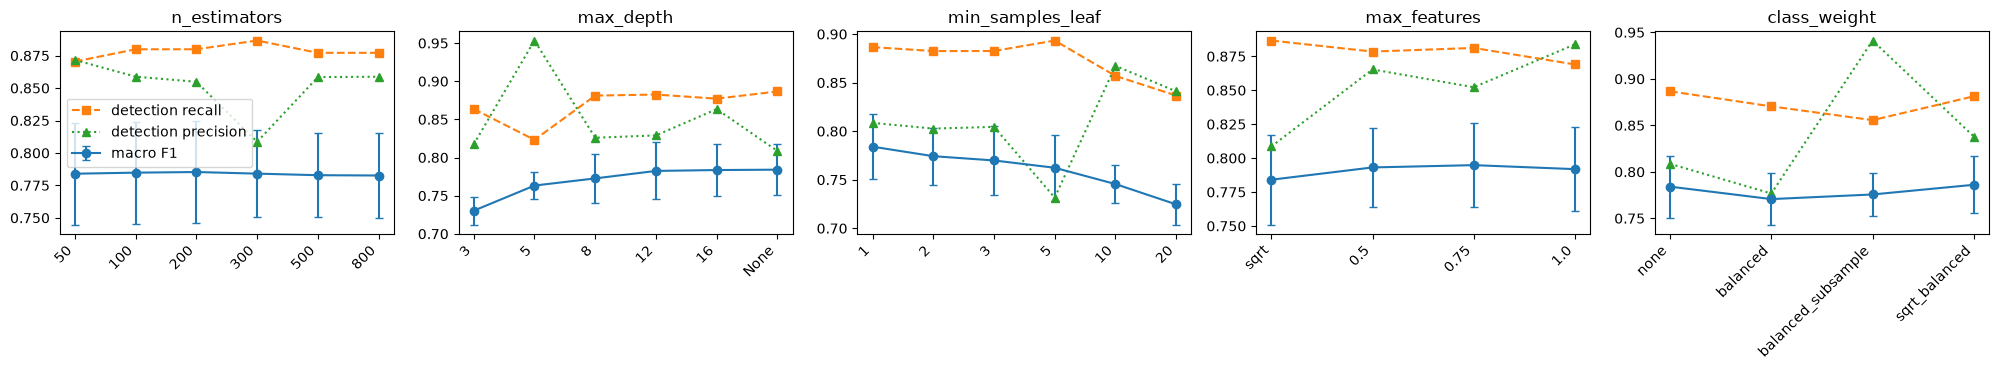

In [ ]:
pick_m = sweeps_m[sweeps_m["detection_recall_mean"] >= R_MIN]
pick_m = pick_m.loc[pick_m.groupby(["sweep_param", "sweep_value"])["f1_macro_mean"].idxmax()]

fig, axes = plt.subplots(1, len(SWEEPS_MULTI), figsize=(4 * len(SWEEPS_MULTI), 3.8))
for ax, (param, values) in zip(axes, SWEEPS_MULTI.items()):
    d = pick_m[pick_m["sweep_param"] == param].set_index("sweep_value").reindex([str(v) for v in values])
    x = range(len(d))
    ax.errorbar(x, d["f1_macro_mean"], yerr=d["f1_macro_std"], marker="o", capsize=3, label="macro F1")
    ax.plot(x, d["detection_recall_mean"], marker="s", ls="--", label="detection recall")
    ax.plot(x, d["detection_precision_mean"], marker="^", ls=":", label="detection precision")
    ax.set_xticks(list(x)); ax.set_xticklabels(d.index, rotation=45, ha="right")
    ax.set_title(param)
axes[0].legend()
fig.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "multi_rf_sweeps.png", dpi=150)
plt.show()

## Random search 

In [11]:
configs_m = list(ParameterSampler(SEARCH_SPACE_MULTI, n_iter=40, random_state=42))
named_m = [(f"rf_Multi_{i:02d}", c) for i, c in enumerate(configs_m, start=1)]

rs_tables_m = []
for i, (name, params) in enumerate(named_m, start=1):
    ct, probas = run_and_log_multi(name, params)
    rs_tables_m.append(ct); all_probas_m[name] = probas
    print(f"{i}/{len(named_m)}  {name}  {ct['seconds'].iloc[0]} s")

pool_m = pd.concat(tables_m + [sweeps_m.drop(columns=["sweep_param", "sweep_value"])] + rs_tables_m,
                   ignore_index=True).drop_duplicates(["config", "cut"])

1/40  rf_Multi_01  20 s
2/40  rf_Multi_02  21 s
3/40  rf_Multi_03  9 s
4/40  rf_Multi_04  35 s
5/40  rf_Multi_05  20 s
6/40  rf_Multi_06  9 s
7/40  rf_Multi_07  17 s
8/40  rf_Multi_08  17 s
9/40  rf_Multi_09  19 s
10/40  rf_Multi_10  18 s
11/40  rf_Multi_11  18 s
12/40  rf_Multi_12  45 s
13/40  rf_Multi_13  11 s
14/40  rf_Multi_14  16 s
15/40  rf_Multi_15  8 s
16/40  rf_Multi_16  16 s
17/40  rf_Multi_17  20 s
18/40  rf_Multi_18  11 s
19/40  rf_Multi_19  38 s
20/40  rf_Multi_20  29 s
21/40  rf_Multi_21  35 s
22/40  rf_Multi_22  14 s
23/40  rf_Multi_23  9 s
24/40  rf_Multi_24  23 s
25/40  rf_Multi_25  14 s
26/40  rf_Multi_26  30 s
27/40  rf_Multi_27  31 s
28/40  rf_Multi_28  21 s
29/40  rf_Multi_29  8 s
30/40  rf_Multi_30  9 s
31/40  rf_Multi_31  24 s
32/40  rf_Multi_32  16 s
33/40  rf_Multi_33  51 s
34/40  rf_Multi_34  24 s
35/40  rf_Multi_35  9 s
36/40  rf_Multi_36  49 s
37/40  rf_Multi_37  8 s
38/40  rf_Multi_38  15 s
39/40  rf_Multi_39  10 s
40/40  rf_Multi_40  15 s


## Ranking

In [15]:
best_r = best_per_config_multi(pool_m, 0.75)
print(f"R_min={0,75}: {len(best_r)} configs pass")
display(best_r.sort_values("f1_macro_mean", ascending=False).head(5)[SHOW_M].round(3))

R_min=(0, 75): 64 configs pass


,config,cut,detection_recall_mean,f1_macro_mean,f1_macro_std,missed_failures_mean,false_alarms_mean,recall_TWF_mean,recall_HDF_mean,recall_PWF_mean,recall_OSF_mean
187,max_features=0.75,0.25,0.881,0.795,0.031,5.867,7.667,0.114,0.996,0.984,0.953
539,rf_Multi_39,0.25,0.876,0.794,0.029,6.133,8.400,0.114,0.991,0.984,0.934
179,max_features=0.5,0.25,0.878,0.793,0.029,6.000,6.867,0.095,0.996,0.990,0.962
196,max_features=1.0,0.30,0.869,0.792,0.031,6.467,5.800,0.076,0.987,0.984,0.939
289,rf_Multi_08,0.15,0.893,0.790,0.035,5.267,13.133,0.181,1.000,0.984,0.990


## Re-evaluation

In [ ]:
finalists_m = list(best_per_config_multi(pool_m).sort_values("f1_macro_mean", ascending=False).head(5)["config"])
if "baseline" not in finalists_m:
    finalists_m.append("baseline")

parts = [pool_m[pool_m["config"].isin(finalists_m)].assign(seed=42)]
for seed in [7, 123, 2026]:
    for name in finalists_m:
        eff = {**BASELINE_MULTI, **PARAMS_M[name]}
        _, probas = evaluate_multi(make_rf(**resolve_params(eff, CW)), X_m, y_m, random_state=seed)
        ct = cut_table_multi(probas, CUTS)
        ct.insert(0, "config", name); ct["seed"] = seed
        parts.append(ct)
        print(seed, name)
all_seeds_m = pd.concat(parts, ignore_index=True)

agg_m = (all_seeds_m.groupby(["config", "cut"])
         .agg(det_recall=("detection_recall_mean", "mean"), det_recall_sd=("detection_recall_mean", "std"),
              det_precision=("detection_precision_mean", "mean"),
              f1_macro=("f1_macro_mean", "mean"), f1_macro_sd=("f1_macro_mean", "std"),
              missed=("missed_failures_mean", "mean"), false_alarms=("false_alarms_mean", "mean"),
              rec_TWF=("recall_TWF_mean", "mean"), rec_HDF=("recall_HDF_mean", "mean"),
              rec_PWF=("recall_PWF_mean", "mean"), rec_OSF=("recall_OSF_mean", "mean")).reset_index())
ok = agg_m[agg_m["det_recall"] >= R_MIN]
best_m = ok.loc[ok.groupby("config")["f1_macro"].idxmax()].sort_values("f1_macro", ascending=False)

finalists_table_m = best_m.copy()
finalists_table_m["params"] = finalists_table_m["config"].map(
    lambda n: json.dumps({**BASELINE_MULTI, **PARAMS_M[n]}, sort_keys=True, default=str))
finalists_table_m.round(4).to_csv(ROOT / "results" / "rf_multi_finalists.csv", index=False)
display(finalists_table_m.round(3))

7 max_features=0.75
7 rf_Multi_39
7 max_features=0.5
7 max_features=1.0
7 rf_Multi_08
7 baseline
123 max_features=0.75
123 rf_Multi_39
123 max_features=0.5
123 max_features=1.0
123 rf_Multi_08
123 baseline
2026 max_features=0.75
2026 rf_Multi_39
2026 max_features=0.5
2026 max_features=1.0
2026 rf_Multi_08
2026 baseline


,config,cut,det_recall,det_recall_sd,det_precision,f1_macro,f1_macro_sd,missed,false_alarms,rec_TWF,rec_HDF,rec_PWF,rec_OSF,params
43,rf_Multi_39,0.25,0.880,0.004,0.846,0.801,0.006,5.917,8.117,0.148,0.988,0.984,0.940,"{""class_weight"": ""none"", ""max_depth"": null, ""m..."
27,max_features=1.0,0.25,0.880,0.005,0.848,0.800,0.007,5.933,7.950,0.143,0.990,0.984,0.943,"{""class_weight"": ""none"", ""max_depth"": null, ""m..."
19,max_features=0.75,0.25,0.881,0.001,0.864,0.799,0.003,5.900,7.067,0.121,0.994,0.985,0.957,"{""class_weight"": ""none"", ""max_depth"": null, ""m..."
11,max_features=0.5,0.25,0.880,0.003,0.867,0.794,0.003,5.950,6.900,0.107,0.995,0.989,0.965,"{""class_weight"": ""none"", ""max_depth"": null, ""m..."
3,baseline,0.25,0.881,0.003,0.857,0.787,0.005,5.900,7.467,0.098,0.997,0.991,0.975,"{""class_weight"": ""none"", ""max_depth"": null, ""m..."
33,rf_Multi_08,0.15,0.891,0.005,0.766,0.785,0.005,5.383,13.667,0.171,1.000,0.984,0.987,"{""class_weight"": ""none"", ""max_depth"": 12, ""max..."


## Chosen configuration

,precision,recall,f1,f1_std,missed_per_fold
No failure,0.996,0.995,0.996,0.001,NaN
TWF,0.164,0.095,0.112,0.101,5.733
HDF,0.914,0.996,0.951,0.044,0.067
PWF,0.973,0.990,0.980,0.033,0.000
OSF,0.896,0.962,0.927,0.041,0.200


macro F1 = 0.793 ± 0.029


,pred No failure,pred TWF,pred HDF,pred PWF,pred OSF
actual No failure,7197.7,19.7,8.0,2.0,4.7
actual TWF,28.7,3.3,0.0,0.0,3.0
actual HDF,0.3,0.0,78.7,0.0,0.0
actual PWF,0.0,0.0,0.0,61.3,0.7
actual OSF,1.0,1.7,0.0,0.0,68.3


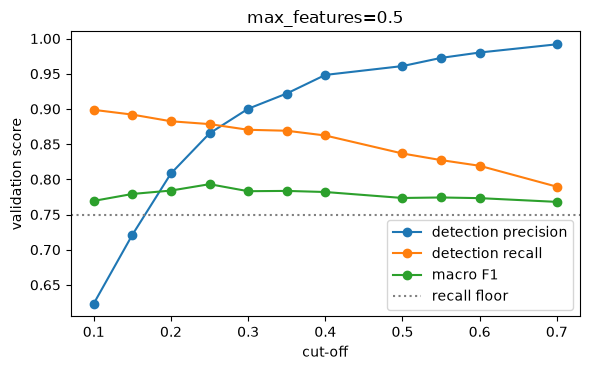

In [ ]:

CHOSEN_M, CUT_M = "max_features=0.5", 0.25         # fill in after reading the table above

def two_stage(proba, cut):
    """Stage 1: failure if 1 - P(no failure) >= cut. Stage 2: most probable failure type."""
    return np.where(1 - proba[:, 0] >= cut, 1 + proba[:, 1:].argmax(axis=1), 0)


s = summarize_multi(metrics_at_cut_multi(all_probas_m[CHOSEN_M], CUT_M))
per_class = pd.DataFrame({
    "precision": [s[f"precision_{n}_mean"] for n in NAMES],
    "recall": [s[f"recall_{n}_mean"] for n in NAMES],
    "f1": [s[f"f1_{n}_mean"] for n in NAMES],
    "f1_std": [s[f"f1_{n}_std"] for n in NAMES],
    "missed_per_fold": [np.nan] + [s[f"missed_{n}_mean"] for n in NAMES[1:]],
}, index=CLASSES)
display(per_class.round(3))
print(f"macro F1 = {s['f1_macro_mean']:.3f} ± {s['f1_macro_std']:.3f}")


N_REPEATS = 3
cm = sum(confusion_matrix(f["y_val"], two_stage(f["proba"], CUT_M), labels=LABELS)
         for f in all_probas_m[CHOSEN_M]) / N_REPEATS
display(pd.DataFrame(cm.round(1), index=[f"actual {c}" for c in CLASSES],
                     columns=[f"pred {c}" for c in CLASSES]))


ct_c = cut_table_multi(all_probas_m[CHOSEN_M], CUTS + [0.55, 0.6, 0.7])
fig, ax = plt.subplots(figsize=(6, 3.8))
for col, lab in [("detection_precision_mean", "detection precision"),
                 ("detection_recall_mean", "detection recall"), ("f1_macro_mean", "macro F1")]:
    ax.plot(ct_c["cut"], ct_c[col], marker="o", label=lab)
ax.axhline(R_MIN, color="grey", ls=":", label="recall floor")
ax.set(xlabel="cut-off", ylabel="validation score", title=CHOSEN_M)
ax.legend(); fig.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "multi_rf_cut.png", dpi=150)
plt.show()

In [ ]:
candidate_m = {"model": "RF", "task": "multi", "name": CHOSEN_M,
               "params": {**BASELINE_MULTI, **PARAMS_M[CHOSEN_M]}, "cut": CUT_M, "features": SELECTED,
               "rule": "highest macro F1 with mean detection recall >= 0.75, averaged over 4 CV seeds"}
json.dump(candidate_m, open(ROOT / "results" / "rf_multi_candidate.json", "w"), indent=2, default=str)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12356\3469414134.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\ASUS\\Desktop\\Mestrado\\AC\\ai4i-predictive-maintenance\\results\\rf_multi_candidate.json' mode='w' encoding='cp1252'>
  json.dump(candidate_m, open(ROOT / "results" / "rf_multi_candidate.json", "w"), indent=2, default=str)
